In [3]:
import pandas as pd

df = pd.read_excel("../Data/Online Retail.xlsx", engine="openpyxl")

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

FileNotFoundError: [Errno 2] No such file or directory: '../Data/Online Retail.xlsx'

In [4]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'Online Retail.xlsx'

In [5]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\KUNAL\Downloads\Online Retail.xlsx"
)

print("Dataset loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\KUNAL\\Downloads\\Online Retail.xlsx'

In [1]:
import pandas as pd

df = pd.read_excel("../Data/Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.shape

(541909, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [ ]:
df_clean = df.dropna(subset=["CustomerID"])

print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))





Original rows: 541909
Rows after cleaning: 406829


In [11]:
# Remove cancelled orders
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]

print("Rows after removing cancelled orders:", len(df_clean))

Rows after removing cancelled orders: 397924


In [12]:
print("Negative quantities:", (df_clean["Quantity"] <= 0).sum())
print("Invalid prices:", (df_clean["UnitPrice"] <= 0).sum())

Negative quantities: 0
Invalid prices: 40


In [13]:
# Keep only valid sales transactions
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (397884, 8)


In [14]:
df_clean["Sales"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print(df_clean[["Quantity", "UnitPrice", "Sales"]].head())

   Quantity  UnitPrice  Sales
0         6       2.55  15.30
1         6       3.39  20.34
2         8       2.75  22.00
3         6       3.39  20.34
4         6       3.39  20.34


In [15]:
customer_sales = (
    df_clean.groupby("CustomerID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

customer_sales.head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Sales, dtype: float64

In [16]:
total_customers = df_clean["CustomerID"].nunique()

print("Total unique customers:", total_customers)

Total unique customers: 4338


In [17]:
total_revenue = df_clean["Sales"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 8911407.9


In [18]:
average_transaction = df_clean["Sales"].mean()

print("Average Transaction Value:", round(average_transaction, 2))

Average Transaction Value: 22.4


In [19]:
top_products = (
    df_clean.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100448.15
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68844.33
ASSORTED COLOUR BIRD ORNAMENT          56580.34
Manual                                 53779.93
RABBIT NIGHT LIGHT                     51346.20
Name: Sales, dtype: float64


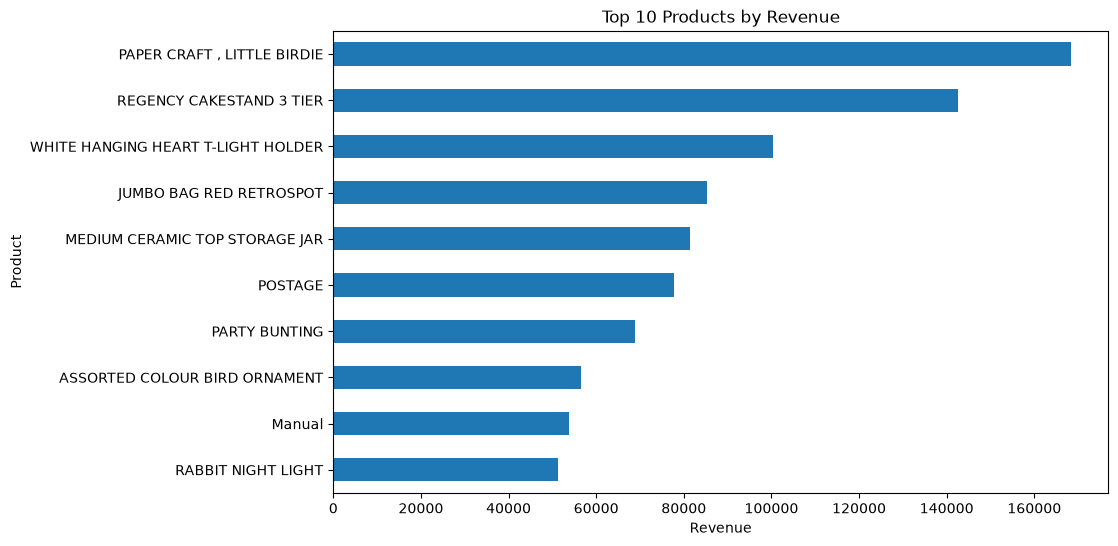

In [20]:
import matplotlib.pyplot as plt

top_products.sort_values().plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.show()

In [21]:
top_quantity_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_quantity_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
POPCORN HOLDER                        30931
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


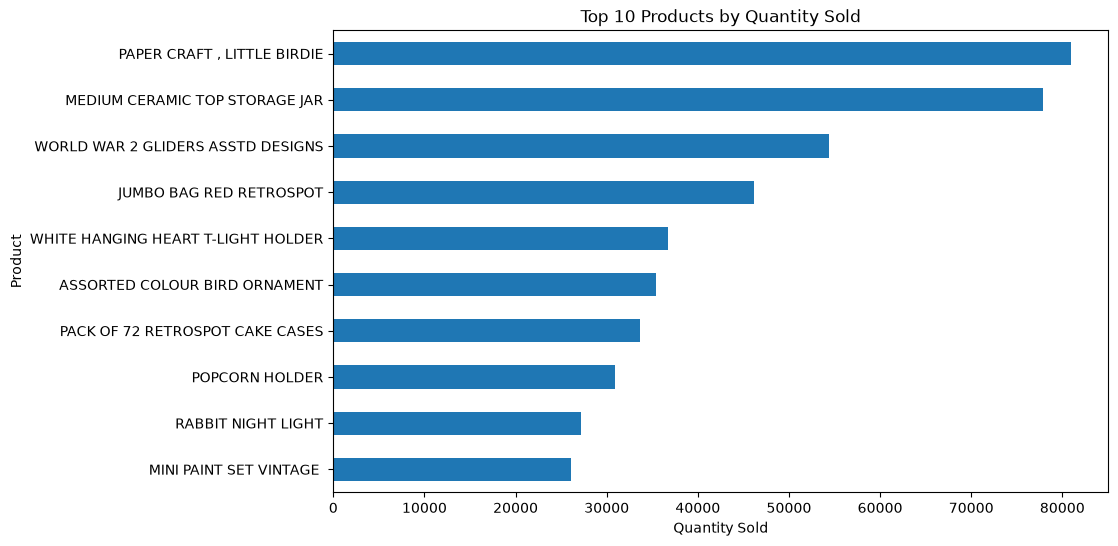

In [22]:
top_quantity_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.show()

In [23]:
customer_orders = (
    df_clean.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print(customer_orders)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


In [24]:
country_sales = (
    df_clean.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))

Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: Sales, dtype: float64


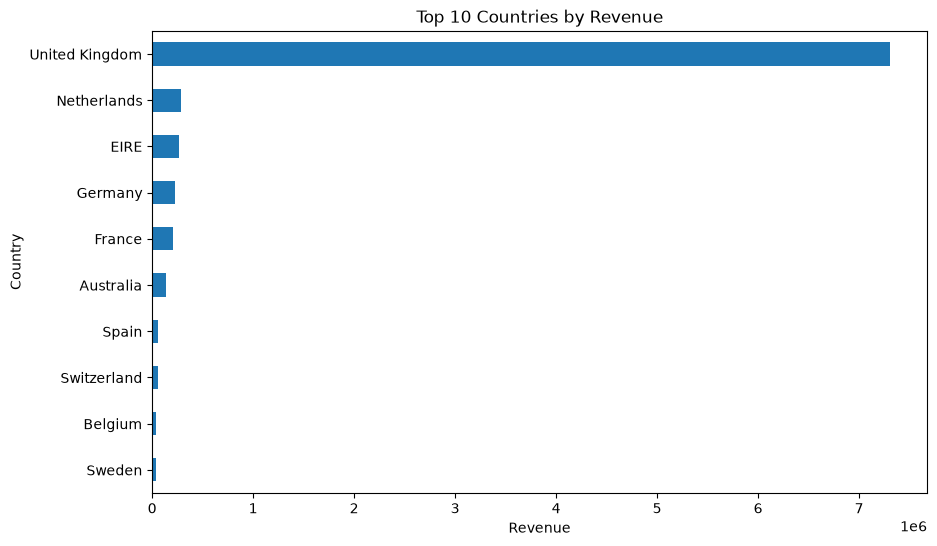

In [25]:
country_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.show()

In [26]:
reference_date = df_clean["InvoiceDate"].max()

print("Latest transaction date:", reference_date)

Latest transaction date: 2011-12-09 12:50:00


In [27]:
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40


In [28]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,325,1,77183.60,1,1,5,115
12347.0,1,7,4310.00,5,5,5,555
12348.0,74,4,1797.24,2,4,4,244
12349.0,18,1,1757.55,4,1,4,414
12350.0,309,1,334.40,1,1,2,112


In [29]:
def customer_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "High Value"
    elif row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Loyal"
    elif row["R_Score"] <= 2:
        return "At Risk"
    else:
        return "Regular"


rfm["Segment"] = rfm.apply(customer_segment, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346.0,325,1,77183.60,1,1,5,115,At Risk
12347.0,1,7,4310.00,5,5,5,555,High Value
12348.0,74,4,1797.24,2,4,4,244,Loyal
12349.0,18,1,1757.55,4,1,4,414,Regular
12350.0,309,1,334.40,1,1,2,112,At Risk


In [30]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
At Risk       1542
Regular       1433
High Value     962
Loyal          401
Name: count, dtype: int64


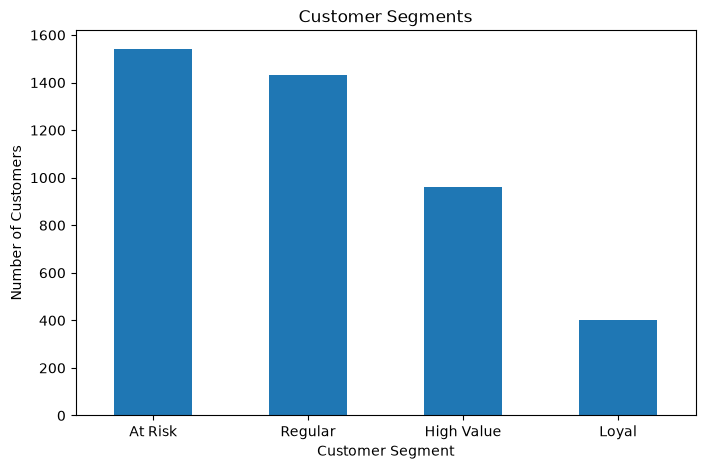

In [31]:
segment_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [34]:
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

print(df_clean["InvoiceDate"].dtype)

datetime64[us]


In [35]:
monthly_sales = (
    df_clean.set_index("InvoiceDate")
    .resample("M")["Sales"]
    .sum()
)

print(monthly_sales)

ValueError: Invalid frequency: M. Failed to parse with error message: ValueError("'M' is no longer supported for offsets. Please use 'ME' instead.")

In [36]:
monthly_sales = (
    df_clean.set_index("InvoiceDate")
    .resample("ME")["Sales"]
    .sum()
)

print(monthly_sales)

InvoiceDate
2010-12-31     572713.890
2011-01-31     569445.040
2011-02-28     447137.350
2011-03-31     595500.760
2011-04-30     469200.361
2011-05-31     678594.560
2011-06-30     661213.690
2011-07-31     600091.011
2011-08-31     645343.900
2011-09-30     952838.382
2011-10-31    1039318.790
2011-11-30    1161817.380
2011-12-31     518192.790
Freq: ME, Name: Sales, dtype: float64


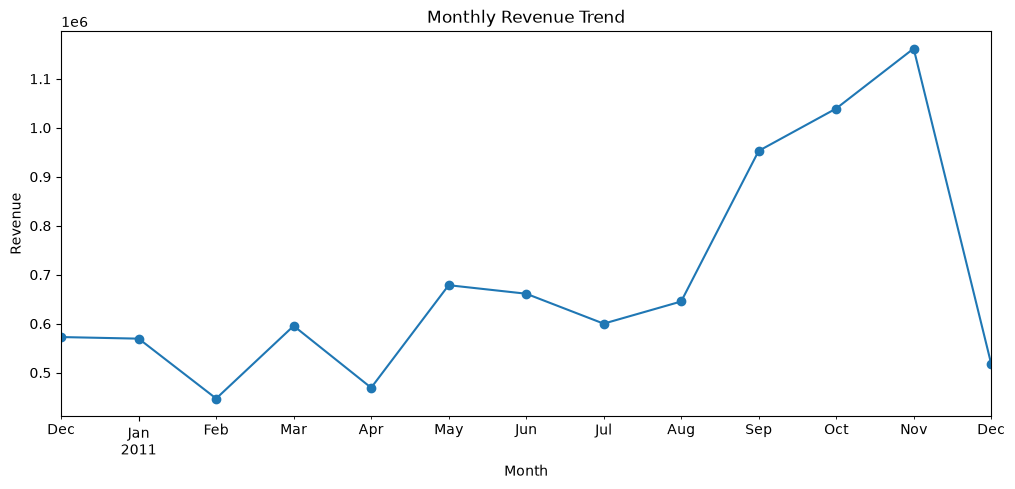

In [37]:
monthly_sales.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [38]:
df_clean.to_csv(
    "../Data/online_retail_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [39]:
import os

print(os.path.exists("../Data/online_retail_cleaned.csv"))

True


In [41]:
import sqlite3

conn = sqlite3.connect("../SQL/ecommerce_analysis.db")

df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Data loaded into SQLite successfully!")

conn.close()

OperationalError: unable to open database file

In [42]:
import os

print("Current folder:")
print(os.getcwd())

Current folder:
c:\All Projects\E-Commerce Customer & Product Analysis\Python


In [43]:
print(os.listdir(".."))

['Data', 'Python', 'SQL']


In [44]:
import os

print(os.getcwd())

c:\All Projects\E-Commerce Customer & Product Analysis\Python


In [45]:
import sqlite3
import os

sql_folder = os.path.abspath("../SQL")
db_path = os.path.join(sql_folder, "ecommerce_analysis.db")

print("Database will be created at:")
print(db_path)

Database will be created at:
c:\All Projects\E-Commerce Customer & Product Analysis\SQL\ecommerce_analysis.db


In [47]:
import sqlite3

conn = sqlite3.connect(db_path)

df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("Database created successfully!")

OperationalError: unable to open database file

In [48]:
import os

sql_folder = os.path.abspath("../SQL")

print(sql_folder)
print(os.path.exists(sql_folder))
print(os.access(sql_folder, os.W_OK))

c:\All Projects\E-Commerce Customer & Product Analysis\SQL
True
True


In [49]:
db_path = os.path.join(sql_folder, "ecommerce_analysis.db")

with open(db_path, "w") as f:
    pass

print("File created successfully:", db_path)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\All Projects\\E-Commerce Customer & Product Analysis\\SQL\\ecommerce_analysis.db'

In [50]:
import os

print("Current folder:")
print(os.getcwd())

print("\nParent folder:")
print(os.path.abspath(".."))

print("\nSQL folder:")
print(os.path.abspath("../SQL"))

print("\nDoes SQL folder exist?")
print(os.path.isdir(os.path.abspath("../SQL")))

Current folder:
c:\All Projects\E-Commerce Customer & Product Analysis\Python

Parent folder:
c:\All Projects\E-Commerce Customer & Product Analysis

SQL folder:
c:\All Projects\E-Commerce Customer & Product Analysis\SQL

Does SQL folder exist?
False


In [51]:
print(os.listdir(os.path.abspath("..")))

['Data', 'Python', 'SQL']


In [52]:
import os

sql_folder = os.path.abspath("../SQL")

os.makedirs(sql_folder, exist_ok=True)

print("SQL folder created:", os.path.exists(sql_folder))


FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'c:\\All Projects\\E-Commerce Customer & Product Analysis\\SQL'

In [53]:
import os

sql_path = os.path.abspath("../SQL")

print("Path:", sql_path)
print("Exists:", os.path.exists(sql_path))
print("Is folder:", os.path.isdir(sql_path))
print("Is file:", os.path.isfile(sql_path))

Path: c:\All Projects\E-Commerce Customer & Product Analysis\SQL
Exists: True
Is folder: False
Is file: True


In [54]:
import os
import sqlite3

sql_folder = os.path.abspath("../SQL")
db_path = os.path.join(sql_folder, "ecommerce_analysis.db")

conn = sqlite3.connect(db_path)

df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("Database created successfully!")
print(db_path)

OperationalError: unable to open database file

In [55]:
import os

sql_folder = os.path.abspath("../SQL")

print("SQL path:", sql_folder)
print("Exists:", os.path.exists(sql_folder))
print("Is folder:", os.path.isdir(sql_folder))
print("Is file:", os.path.isfile(sql_folder))

print("\nParent contents:")
print(os.listdir(os.path.abspath("..")))

SQL path: c:\All Projects\E-Commerce Customer & Product Analysis\SQL
Exists: True
Is folder: False
Is file: True

Parent contents:
['Data', 'Python', 'Sql', 'SQL_old']


In [56]:
import os

sql_folder = os.path.abspath("../SQL")

print("Exists:", os.path.exists(sql_folder))
print("Is folder:", os.path.isdir(sql_folder))

Exists: True
Is folder: True


In [57]:
import os
import sqlite3

sql_folder = os.path.abspath("../SQL")
db_path = os.path.join(sql_folder, "ecommerce_analysis.db")

conn = sqlite3.connect(db_path)

df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("Database created successfully!")
print(db_path)

Database created successfully!
c:\All Projects\E-Commerce Customer & Product Analysis\SQL\ecommerce_analysis.db


In [58]:
import os

print(os.path.exists(db_path))

True


In [59]:
conn = sqlite3.connect(db_path)

query = """
SELECT SUM(Sales) AS Total_Revenue
FROM sales;
"""

result = pd.read_sql_query(query, conn)

conn.close()

result

,Total_Revenue
0,8911407.904


In [60]:
conn = sqlite3.connect(db_path)

query = """
SELECT COUNT(DISTINCT InvoiceNo) AS Total_Orders
FROM sales;
"""

result = pd.read_sql_query(query, conn)

conn.close()

result

,Total_Orders
0,18532


In [61]:
conn = sqlite3.connect(db_path)

query = """
SELECT SUM(Sales) AS Total_Revenue
FROM sales;
"""

result = pd.read_sql_query(query, conn)

conn.close()

result

,Total_Revenue
0,8911407.904


In [62]:
conn = sqlite3.connect(db_path)

query = """
SELECT COUNT(DISTINCT InvoiceNo) AS Total_Orders
FROM sales;
"""

result = pd.read_sql_query(query, conn)

conn.close()

result

,Total_Orders
0,18532


In [63]:
conn = sqlite3.connect(db_path)

query = """
SELECT
    Country,
    SUM(Sales) AS Total_Revenue
FROM sales
GROUP BY Country
ORDER BY Total_Revenue DESC;
"""

country_revenue = pd.read_sql_query(query, conn)

conn.close()

country_revenue.head(10)

,Country,Total_Revenue
0,United Kingdom,7308391.554
1,Netherlands,285446.340
2,EIRE,265545.900
3,Germany,228867.140
4,France,209024.050
5,Australia,138521.310
6,Spain,61577.110
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38378.330
